# Step 3 Retrieval Lab: HR Policy Navigator

**Goal:** redo Step 3 (retrieval) end to end, understand every stage, and close the open gates.

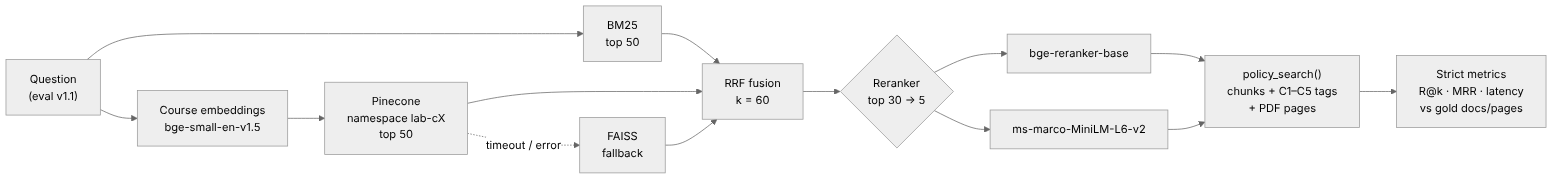

| You will build | Gate it closes |
|---|---|
| Strict recall@k / MRR against **gold docs and gold pages** | 5: inflated metric |
| Three chunking variants (C1 fixed-150, C2 fixed-300, C3 heading-aware) | 8: chunking experiments |
| Embedding cache + Pinecone namespaces `lab-c1..c3` + FAISS fallback | 10: cache, versioning, fallback |
| RRF on string chunk IDs (and a check of the float-ID bug) | 6: hybrid fusion |
| **bge-reranker-base vs ms-marco-MiniLM-L6-v2**  | 7: reranker |
| Page numbers on every chunk → `[C1] p. 403` citations | 9: citations |
| `policy_search()` with its contract test | 12: tests |

**Time:** about 2–3 h, mostly embedding and reranking on CPU. **Run from** `notebooks/` in the repo, with `.env` in the repo root.

**How to read each section:** *Why* (the idea) → *Code* (run it) → *Checkpoint* (what you should see). Sections 1–3 need no API at all, so you can do them offline.

## 0. Setup

**Install once** (in the repo's virtual environment):

```bash
pip install -r requirements.txt
pip install rank-bm25 faiss-cpu sentence-transformers matplotlib
```

`sentence-transformers` pulls in PyTorch (CPU is fine). The first reranker run downloads about 1.1 GB (bge-reranker-base) and 90 MB (MiniLM) from Hugging Face.

**`.env`** (same names as the repo's `.env.example`): `QWEN_API_KEY`, `QWEN_BASE_URL`, `EMBEDDING_API_KEY`, `EMBEDDING_BASE_URL`, `PINECONE_API_KEY`.

> `LAB_OFFLINE=1` swaps the course endpoint, Pinecone and the rerankers for small fakes. It exists only to smoke-test this notebook's code paths, and **its numbers mean nothing**. Leave it unset for the real run.

In [3]:
import os, sys, json, time, hashlib, random, re, statistics as st
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = REPO / "data"
LAB = DATA / "lab"; LAB.mkdir(parents=True, exist_ok=True)
OFFLINE = os.getenv("LAB_OFFLINE") == "1"

try:
    from dotenv import load_dotenv; load_dotenv(REPO / ".env")
except ImportError:
    pass

CFG = dict(
    embed_model="bge-small-en-v1.5", embed_dim=384, embed_batch=64,
    query_instruction="Represent this sentence for searching relevant passages: ",
    pinecone_index="hr-policy-navigator", ns_prefix="lab-",          # Rajat's default namespace stays untouched
    top_k_each=50, rrf_k=60, rerank_in=30, top_out=5, context_tokens=2500,
    rerankers={"bge-base": "BAAI/bge-reranker-base", "minilm-l6": "cross-encoder/ms-marco-MiniLM-L6-v2"},
    variants=["c1", "c2", "c3"],
)
print("Repo:", REPO, "| offline smoke test:", OFFLINE)
assert (DATA / "processed").exists(), "Run this notebook from the repo's notebooks/ folder"

Repo: c:\Shubhi\AI&ML Course\capstone\Capstone-HR-Policy-Navigator-Project | offline smoke test: False


### 0.1 Core functions (chunkers, page tagging, metrics, RRF)

Read this cell once. It's small, and each later section uses it. The `c1` chunker reproduces the repo's `chunker.py` exactly, so C1 numbers are comparable with the team's earlier work.

In [4]:
"""Core lab code (chunkers, page tagging, BM25, metrics) — copied verbatim into the notebook."""
import re, json, math
from collections import Counter, defaultdict
from pathlib import Path

# ---------------------------------------------------------------- corpus
def load_docs(processed_dir):
    return {p.stem: p.read_text(encoding="utf-8").strip()
            for p in sorted(Path(processed_dir).glob("doc_*.txt"))}

# ---------------------------------------------------------------- chunkers
def chunk_fixed(text, size=150, overlap=20):
    """C1/C2: fixed word windows (C1 = the repo's current 150/20 chunker)."""
    w = text.split()
    if len(w) <= size:
        return [" ".join(w)]
    out, start = [], 0
    while start < len(w):
        out.append(" ".join(w[start:start + size]))
        start += size - overlap          # same as repo: keeps a short tail window
    return out

_HEAD = re.compile(r"^[A-Z0-9][^.!?:;]{2,70}$")

def is_heading(line, nxt):
    """Heuristic heading: short, no closing punctuation, not a wrapped sentence."""
    s = line.strip()
    if not s or not _HEAD.match(s) or len(s.split()) > 9:
        return False
    if s.endswith(",") or s.lower().startswith(("and ", "or ", "the ", "to ", "of ")):
        return False
    return bool(nxt.strip())

def blocks_by_heading(text):
    """Split a page-window document into (heading, body) blocks; unwrap hard line breaks."""
    lines = text.splitlines()
    blocks, head, body = [], "", []
    for i, ln in enumerate(lines):
        nxt = lines[i + 1] if i + 1 < len(lines) else ""
        if is_heading(ln, nxt):
            if body:
                blocks.append((head, " ".join(body)))
            head, body = ln.strip(), []
        elif ln.strip():
            body.append(ln.strip())
    if body:
        blocks.append((head, " ".join(body)))
    return blocks

_SENT = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(])")

def chunk_structural(text, max_words=200, min_words=40):
    """C3: heading-aware packing. Each chunk = 'heading: body', never cuts mid-sentence,
    merges small sections, splits big ones by sentence."""
    chunks, cur, cur_head = [], [], ""
    def flush():
        nonlocal cur
        if cur:
            body = " ".join(cur)
            chunks.append(f"{cur_head}: {body}" if cur_head else body)
            cur = []
    for head, body in blocks_by_heading(text):
        sents = []
        for s in _SENT.split(body):          # hard cap: split run-on "sentences" (lists)
            ws = s.split()
            sents += [" ".join(ws[i:i + max_words]) for i in range(0, len(ws), max_words)] or [s]
        if cur and (len(" ".join(cur).split()) >= min_words):
            flush()
        if not cur:
            cur_head = head
        elif head:
            cur.append(f"{head}:")
        for s in sents:
            if cur and len(" ".join(cur + [s]).split()) > max_words:
                flush()
                cur_head = head
            cur.append(s)
    flush()
    return [c for c in chunks if c.split()]

def build_chunks(docs, variant):
    fn = {"c1": lambda t: chunk_fixed(t, 150, 20),
          "c2": lambda t: chunk_fixed(t, 300, 50),
          "c3": lambda t: chunk_structural(t, 200, 40)}[variant]
    rows = []
    for doc_id, text in docs.items():
        for i, c in enumerate(fn(text)):
            rows.append({"chunk_id": f"{doc_id}::{variant}::{i:03d}", "doc_id": doc_id,
                         "variant": variant, "chunk_index": i, "text": c})
    return rows

# ---------------------------------------------------------------- page tagging (for citations)
_TOK = re.compile(r"[a-z0-9$]+")
def _shingles(text, n=6):
    t = _TOK.findall(text.lower())
    return {" ".join(t[i:i + n]) for i in range(max(0, len(t) - n + 1))}

def tag_pages(chunks, doc_pages, page_text):
    """Attach the PDF page numbers each chunk's text comes from (searching only its doc's pages)."""
    cache = {}
    for ch in chunks:
        cand = doc_pages.get(ch["doc_id"], [])
        s = _shingles(ch["text"])
        hits = []
        for p in cand:
            if p not in cache:
                cache[p] = _shingles(page_text[p - 1])
            if s and len(s & cache[p]) / len(s) >= 0.15:
                hits.append(p)
        ch["pages"] = hits or cand[:1]
    return chunks

# ---------------------------------------------------------------- BM25
def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

# ---------------------------------------------------------------- metrics
def is_hit(chunk, item, level="doc"):
    if level == "doc":
        return chunk["doc_id"] in item["gold_doc_ids"]
    return bool(set(chunk.get("pages", [])) & set(item["gold_pages"]))

def evaluate(ranked_by_qid, eval_items, chunk_lookup, ks=(1, 3, 5, 10), level="doc"):
    """ranked_by_qid: {qid: [chunk_id, ...]} best first."""
    hits = {k: 0 for k in ks}; rr = []
    per_q = {}
    for it in eval_items:
        ranked = ranked_by_qid[it["id"]]
        rank = next((i for i, cid in enumerate(ranked, 1) if is_hit(chunk_lookup[cid], it, level)), None)
        per_q[it["id"]] = rank
        rr.append(1 / rank if rank else 0.0)
        for k in ks:
            hits[k] += bool(rank and rank <= k)
    n = len(eval_items)
    out = {f"R@{k}": round(hits[k] / n, 3) for k in ks}
    out["MRR"] = round(sum(rr) / n, 3)
    return out, per_q

def rrf(rankings, k=60):
    score = defaultdict(float); src = defaultdict(list)
    for name, ranking in rankings.items():
        for r, cid in enumerate(ranking, 1):
            score[cid] += 1.0 / (k + r); src[cid].append(name)
    order = sorted(score, key=lambda c: (-score[c], c))
    return order, dict(score), dict(src)

## 1. Gate 5: measure retrieval honestly

**Why.** The repo's `check_retrieval_hit` counts a chunk as a hit when about 30% of the gold answer's words appear in it. Words like *the, and, of, GitLab, team, member* are everywhere, so unrelated chunks pass. A metric that rewards the wrong chunk can't tell good retrieval from bad.

**Strict rule (from now on):** a retrieved chunk is a hit when it comes from a **gold doc** (`gold_doc_ids`) or, stricter, from a **gold PDF page** (`gold_pages`). Both were derived from each question's `source_reference` and are stored in `gitlab_eval_questions_v1_1.json`.

In [5]:
docs = load_docs(DATA / "processed")
EVAL = json.load(open(DATA / "evaluation" / "gitlab_eval_questions_v1_1.json", encoding="utf-8"))
PAGES = json.load(open(DATA / "processed" / "pdf_pages.json", encoding="utf-8"))           # 1,338 page texts
PMAP = json.load(open(DATA / "processed" / "doc_page_map.json", encoding="utf-8"))
DOC_PAGES = {d: v for d, v in PMAP["doc_pages"].items()}
print(f"{len(docs)} docs | {len(EVAL)} questions | {len(PAGES)} PDF pages")
q1 = next(e for e in EVAL if e["id"] == 1)
print("\nQ1:", q1["query"], "\n  gold pages:", q1["gold_pages"], " gold docs:", q1["gold_doc_ids"])

502 docs | 80 questions | 1338 PDF pages

Q1: What is the total home office stipend for a newly hired team member, and how is it expensed? 
  gold pages: [55, 65]  gold docs: ['doc_019', 'doc_022']


In [6]:
# The old metric, verbatim from src/evaluation/evaluate_retrieval.py
def old_hit(chunk_text, gold_answer):
    gold_lower = gold_answer.lower(); text_lower = chunk_text.lower()
    gold_numbers = set(re.findall(r"\$?\d+(?:[,.]?\d+)*", gold_lower))
    if gold_numbers and sum(1 for n in gold_numbers if n in text_lower) >= len(gold_numbers) * 0.5:
        return True
    gw, tw = set(gold_lower.split()), set(text_lower.split())
    return len(gw & tw) / len(gw) >= 0.3

c1_tmp = build_chunks(docs, "c1"); random.seed(0)
p_false = np.mean([old_hit(random.choice(c1_tmp)["text"], e["gold_answer"]) for e in EVAL for _ in range(20)])
print(f"Old metric: a RANDOM chunk counts as a hit {p_false:.1%} of the time")
print(f"=> chance that >=1 of 10 random chunks 'hits': {1-(1-p_false)**10:.0%}")

Old metric: a RANDOM chunk counts as a hit 23.8% of the time
=> chance that >=1 of 10 random chunks 'hits': 93%


**Checkpoint:** about **23.8%** and **93%**. So the old recall@10 = 100% was almost guaranteed, whatever the retriever did.

## 2. Gate 8: chunking experiments

**Why.** Chunk size trades **precision** (small chunks: the passage is about one thing) against **context** (big chunks: the condition and the exception stay together). The docs are 2–3-page windows cut from the PDF, so the cut points ignore section boundaries.

| Variant | Rule | Idea |
|---|---|---|
| **C1** | 150 words, 20 overlap (the repo today) | Baseline |
| **C2** | 300 words, 50 overlap | More context per chunk |
| **C3** | Split at headings, never mid-sentence, ≤200 words, heading prefixed ("Growth and Development Fund: …") | Chunks follow the document's own structure; the heading adds context for both BM25 and embeddings |

Every chunk also gets the **PDF pages** its text comes from (6-word shingle overlap with that doc's pages). That gives us page-level metrics now and `p. 403` citations in Step 4.

**Concrete example:** the same passage (doc_135, the Growth and Development Fund) in each variant:

In [7]:
CHUNKS = {}
for v in CFG["variants"]:
    CHUNKS[v] = tag_pages(build_chunks(docs, v), DOC_PAGES, PAGES)
LOOKUP = {c["chunk_id"]: c for v in CHUNKS for c in CHUNKS[v]}

rows = []
for v, ch in CHUNKS.items():
    L = [len(c["text"].split()) for c in ch]
    rows.append({"variant": v, "chunks": len(ch), "median_words": st.median(L), "max_words": max(L),
                 "avg_pages_per_chunk": round(np.mean([len(c["pages"]) for c in ch]), 2)})
display(pd.DataFrame(rows))

for v in CFG["variants"]:
    hit = next(c for c in CHUNKS[v] if c["doc_id"] == "doc_135" and "Growth and Development Fund" in c["text"])
    print(f"--- {v}  {hit['chunk_id']}  pages={hit['pages']}  ({len(hit['text'].split())} words)\n{hit['text'][:420]}…\n")

,variant,chunks,median_words,max_words,avg_pages_per_chunk
0,c1,3364,150.0,150,1.29
1,c2,1860,300.0,300,1.46
2,c3,3951,80.0,208,1.21


--- c1  doc_135::c1::000  pages=[403]  (150 words)
This is a company-wide position and is not specific to any single region. GitLab remains committed to offering competitive, locally relevant benefits and will continue to explore options that better align with the company’s structure. Growth and Development Fund Your professional growth matters to us and strengthens our entire team. That’s why we provide up to $10,000 each year specifically for your career developmen…

--- c2  doc_135::c2::000  pages=[403]  (300 words)
This is a company-wide position and is not specific to any single region. GitLab remains committed to offering competitive, locally relevant benefits and will continue to explore options that better align with the company’s structure. Growth and Development Fund Your professional growth matters to us and strengthens our entire team. That’s why we provide up to $10,000 each year specifically for your career developmen…

--- c3  doc_135::c3::000  pages=[403]  (103 words)
T

**Checkpoint:** C1 has **3,364** chunks (exactly as many as the repo), C2 about 1,860, and C3 about 3,950 with a median of about 80 words. In the example, C3 starts with its heading. C1 starts wherever word 1, 131, 261… happened to fall.

*Try:* change C3 to `max_words=300` in `build_chunks` and see how the median moves.

## 3. BM25: the keyword baseline (no API)

**Why.** BM25 scores a chunk by how many query words it contains, weighted by how rare each word is (IDF), and dampened for long chunks. It is very good at exact terms: *COBRA*, *Navan*, *$1,500*, *Tilt*. Dense embeddings sometimes blur these.

In [8]:
from rank_bm25 import BM25Okapi
BM25 = {}
for v, ch in CHUNKS.items():
    BM25[v] = (BM25Okapi([tokenize(c["text"]) for c in ch]), [c["chunk_id"] for c in ch])

def bm25_search(v, query, k):
    bm, ids = BM25[v]; s = bm.get_scores(tokenize(query))
    top = np.argsort(-s)[:k]
    return [(ids[i], float(s[i])) for i in top if s[i] > 0]

RESULTS, RANKED = [], {}
def record(method, v, ranked):
    RANKED[(method, v)] = ranked
    d, _ = evaluate(ranked, EVAL, LOOKUP, level="doc"); p, _ = evaluate(ranked, EVAL, LOOKUP, level="page")
    RESULTS.append({"method": method, "variant": v, **{f"doc_{k}": x for k, x in d.items()}, "page_R@5": p["R@5"], "page_MRR": p["MRR"]})
    return d

for v in CFG["variants"]:
    ranked = {e["id"]: [cid for cid, _ in bm25_search(v, e["query"], 10)] for e in EVAL}
    print(v, record("bm25", v, ranked))

print("\nQ1 top-3 (C3):")
for cid, s in bm25_search("c3", q1["query"], 3):
    c = LOOKUP[cid]; print(f"  {s:6.2f}  {cid}  pages={c['pages']}  gold={'YES' if c['doc_id'] in q1['gold_doc_ids'] else 'no'}")

c1 {'R@1': 0.625, 'R@3': 0.85, 'R@5': 0.938, 'R@10': 0.975, 'MRR': 0.751}
c2 {'R@1': 0.65, 'R@3': 0.85, 'R@5': 0.9, 'R@10': 0.95, 'MRR': 0.761}
c3 {'R@1': 0.625, 'R@3': 0.85, 'R@5': 0.95, 'R@10': 0.963, 'MRR': 0.748}

Q1 top-3 (C3):
   33.56  doc_019::c3::000  pages=[55]  gold=YES
   32.42  doc_022::c3::006  pages=[65]  gold=YES
   32.11  doc_251::c3::002  pages=[751]  gold=no


**Checkpoint (computed offline for this lab; your run should match):**

| Variant | R@1 | R@5 | R@10 | MRR |
|---|---|---|---|---|
| C1 | 0.625 | 0.938 | 0.975 | 0.751 |
| C2 | 0.650 | 0.900 | 0.950 | 0.761 |
| C3 | 0.625 | 0.950 | 0.963 | 0.748 |

With 80 questions, one question = 1.25 points, so these three are close to a tie on BM25.

## 4. Embeddings with a cache (bge-small-en-v1.5, run locally)

**Why local.** The API endpoints don't serve embeddings (port 1035 returned nothing), so we run the same open model, `BAAI/bge-small-en-v1.5` (384-d), with sentence-transformers on CPU. ADR-008 records this.

**Why a cache.** About 9,200 chunks across three variants take several minutes on CPU. Keying each vector by `sha1(text)` means re-runs, the FAISS fallback and later experiments cost nothing.

**BGE query instruction.** bge-small-en-v1.5 was trained with an instruction prefix on **queries** (not passages) for retrieval: *"Represent this sentence for searching relevant passages: "*. We test with and without it in section 6.

In [9]:
PROVIDER = "fake" if OFFLINE else (os.getenv("EMBEDDING_PROVIDER") or "local")
CACHE_F = LAB / ("embedding_cache.npz" if PROVIDER == "api" else f"embedding_cache_{PROVIDER}.npz")   # shared with scripts/build_index.py
CACHE = dict(np.load(CACHE_F, allow_pickle=False)) if CACHE_F.exists() else {}
key = lambda t: hashlib.sha1(t.encode("utf-8")).hexdigest()

if OFFLINE:
    def _embed_api(texts):
        out = []
        for t in texts:
            v = np.zeros(CFG["embed_dim"])
            for w in tokenize(t):
                v[int(hashlib.md5(w.encode()).hexdigest(), 16) % CFG["embed_dim"]] += 1
            out.append(v / (np.linalg.norm(v) or 1))
        return out
else:
    sys.path.insert(0, str(REPO))
    from src.llm.client import Embedder            # local BAAI/bge-small-en-v1.5 (course has no embeddings endpoint)
    _emb = Embedder()
    def _embed_api(texts):
        return [np.asarray(v) for v in _emb.embed(texts)]

def embed(texts, save_every=40):
    todo = [t for t in dict.fromkeys(texts) if key(t) not in CACHE]
    for i in range(0, len(todo), CFG["embed_batch"]):
        batch = todo[i:i + CFG["embed_batch"]]
        for attempt in range(4):
            try:
                vecs = _embed_api(batch); break
            except Exception as ex:
                if attempt == 3: raise
                time.sleep(2 ** attempt); print("retry", attempt + 1, type(ex).__name__)
        for t, v in zip(batch, vecs):
            assert len(v) == CFG["embed_dim"]
            CACHE[key(t)] = np.asarray(v, dtype=np.float32)
        if len(todo) > 100 and (i // CFG["embed_batch"]) % save_every == 0:
            np.savez(CACHE_F, **CACHE); print(f"  {min(i + CFG['embed_batch'], len(todo))}/{len(todo)} embedded")
    if len(todo) > 50:                       # chunk batches only; single queries stay in memory (saving 14 MB per query is slow)
        np.savez(CACHE_F, **CACHE)
    M = np.stack([CACHE[key(t)] for t in texts])
    return M / np.maximum(np.linalg.norm(M, axis=1, keepdims=True), 1e-12)

VEC = {}
for v in CFG["variants"]:
    t0 = time.time(); VEC[v] = embed([c["text"] for c in CHUNKS[v]])
    print(v, VEC[v].shape, f"{time.time() - t0:.0f}s")
print("norm check:", np.round(np.linalg.norm(VEC['c1'][:3], axis=1), 3))

c:\Shubhi\AI&ML Course\capstone\Capstone-HR-Policy-Navigator-Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1811.71it/s]


  64/3358 embedded
  2624/3358 embedded
c1 (3364, 384) 291s
  64/1848 embedded
c2 (1860, 384) 318s
  64/3942 embedded
  2624/3942 embedded
c3 (3951, 384) 293s
norm check: [1. 1. 1.]


**Checkpoint:** shapes `(3364, 384)`, about `(1860, 384)` and about `(3951, 384)`, norms 1.0. A second run of this cell takes seconds (everything comes from the cache).

## 5. Pinecone: one namespace per chunking variant

**Design (ADR-002, approved by the mentor):**
- Same index as the team (`hr-policy-navigator`, 384-d, cosine). **New namespaces** `lab-c1`, `lab-c2`, `lab-c3`, so Rajat's default namespace is never touched.
- Vector ID = our **string** `chunk_id` (e.g. `doc_135::c3::004`).
- Metadata = `doc_id`, `variant`, `pages` (as strings, because Pinecone lists must be strings). Chunk text stays local (`LOOKUP`): the source of truth is ours.
- Pinecone writes take a moment to become searchable, so we poll the namespace count before querying.

In [10]:
class FakeIndex:                                   # offline smoke test only
    def __init__(self): self.ns = defaultdict(dict)
    def upsert(self, vectors, namespace):
        for x in vectors: self.ns[namespace][x["id"]] = (np.array(x["values"]), x["metadata"])
    def describe_index_stats(self):
        return {"namespaces": {n: {"vector_count": len(d)} for n, d in self.ns.items()}}
    def delete(self, delete_all, namespace): self.ns.pop(namespace, None)
    def query(self, vector, top_k, namespace, include_metadata=True):
        ids = list(self.ns[namespace]); M = np.stack([self.ns[namespace][i][0] for i in ids]); s = M @ np.array(vector)
        o = np.argsort(-s)[:top_k]
        Match = type("Match", (), {})
        res = []
        for i in o:
            m = Match(); m.id, m.score, m.metadata = ids[i], float(s[i]), self.ns[namespace][ids[i]][1]; res.append(m)
        R = type("R", (), {})(); R.matches = res; return R

if OFFLINE:
    index = FakeIndex()
else:
    from pinecone import Pinecone
    pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])
    if CFG["pinecone_index"] not in pc.list_indexes().names():          # new Pinecone account: create it once
        from pinecone import ServerlessSpec
        pc.create_index(name=CFG["pinecone_index"], dimension=CFG["embed_dim"], metric="cosine",
                        spec=ServerlessSpec(cloud="aws", region="us-east-1"))
        while not pc.describe_index(CFG["pinecone_index"]).status["ready"]:
            time.sleep(2)
        print("created index", CFG["pinecone_index"])
    index = pc.Index(CFG["pinecone_index"])

def ns_count(ns):
    s = index.describe_index_stats()
    nss = s["namespaces"] if isinstance(s, dict) else s.namespaces
    n = nss.get(ns)
    return 0 if n is None else (n["vector_count"] if isinstance(n, dict) else n.vector_count)

def upsert_variant(v, batch=100, rebuild=False):
    ns = CFG["ns_prefix"] + v
    if rebuild:
        try: index.delete(delete_all=True, namespace=ns)
        except Exception: pass                                     # namespace didn't exist yet
    if ns_count(ns) == len(CHUNKS[v]) and not rebuild:
        print(ns, "already complete:", len(CHUNKS[v])); return
    for i in range(0, len(CHUNKS[v]), batch):
        rows = CHUNKS[v][i:i + batch]
        index.upsert(namespace=ns, vectors=[{
            "id": c["chunk_id"], "values": VEC[v][i + j].tolist(),
            "metadata": {"doc_id": c["doc_id"], "variant": v, "pages": [str(p) for p in c["pages"]]}}
            for j, c in enumerate(rows)])
    t0 = time.time()
    while ns_count(ns) < len(CHUNKS[v]):
        if time.time() - t0 > 120: raise TimeoutError(ns)
        time.sleep(2)
    print(ns, "upserted and searchable:", ns_count(ns))

for v in CFG["variants"]:
    upsert_variant(v)

created index hr-policy-navigator
lab-c1 upserted and searchable: 3364
lab-c2 upserted and searchable: 1860
lab-c3 upserted and searchable: 3951


### 5.1 Gate 6 check: does the old hybrid code fuse anything?

The old `query_similar` rebuilt each dense result's ID from metadata as `f"{doc_id}_{chunk_index}"`, while BM25 used the in-memory int. If Pinecone returns `chunk_index` as a **float**, the IDs differ (`doc_015_3.0` vs `doc_015_3`), RRF never adds the two scores, and "hybrid" is just the two lists interleaved.

In [11]:
if not OFFLINE:
    probe = index.query(vector=VEC["c1"][0].tolist(), top_k=1, include_metadata=True)       # default namespace = team index
    if probe.matches:
        m = probe.matches[0]; ci = m.metadata.get("chunk_index")
        rebuilt = f'{m.metadata.get("doc_id")}_{ci}'
        print("vector id:", m.id, "| chunk_index type:", type(ci).__name__, "| id rebuilt by old code:", rebuilt)
        print("BUG CONFIRMED: dense and BM25 ids can never match" if rebuilt != m.id else "No mismatch: ids agree")
    else:
        print("Default namespace is empty; nothing to check")

Default namespace is empty; nothing to check


**Checkpoint:** if you see `chunk_index type: float` and **BUG CONFIRMED**, record it in the review. Either way, this lab uses the Pinecone vector `id`, which is always our string `chunk_id`.

## 6. Dense retrieval, the FAISS fallback, and the query instruction

**Why FAISS.** It's the same vectors, held in memory. If Pinecone is slow or down, `policy_search` switches over and marks the result `degraded: true`. The **parity check** shows the two backends rank the same way.

In [12]:
import faiss
FAISS = {}
for v in CFG["variants"]:
    ix = faiss.IndexFlatIP(CFG["embed_dim"]); ix.add(VEC[v].astype(np.float32)); FAISS[v] = ix

def qvec(query, instruct=True):
    return embed([(CFG["query_instruction"] if instruct else "") + query])[0]

def dense_pinecone(v, qv, k):
    r = index.query(vector=qv.tolist(), top_k=k, namespace=CFG["ns_prefix"] + v, include_metadata=True)
    return [(m.id, float(m.score)) for m in r.matches]

def dense_faiss(v, qv, k):
    s, i = FAISS[v].search(qv.reshape(1, -1).astype(np.float32), k)
    ids = [c["chunk_id"] for c in CHUNKS[v]]
    return [(ids[j], float(x)) for x, j in zip(s[0], i[0])]

lat = defaultdict(list)
for v in CFG["variants"]:
    for instruct in (True, False):
        rp, rf = {}, {}
        for e in EVAL:
            qv = qvec(e["query"], instruct)
            t0 = time.perf_counter(); rp[e["id"]] = [c for c, _ in dense_pinecone(v, qv, 10)]; lat[v].append(time.perf_counter() - t0)
            rf[e["id"]] = [c for c, _ in dense_faiss(v, qv, 10)]
        tag = "" if instruct else "-noinstr"
        print(v, tag or "(instr)", "pinecone", record("dense-pinecone" + tag, v, rp))
        if instruct:
            print(v, "        faiss   ", record("dense-faiss", v, rf))
print("\nPinecone query latency p50/p95 (ms):",
      {v: (round(1000 * np.percentile(x, 50)), round(1000 * np.percentile(x, 95))) for v, x in lat.items()})

c1 (instr) pinecone {'R@1': 0.675, 'R@3': 0.85, 'R@5': 0.875, 'R@10': 0.938, 'MRR': 0.767}
c1         faiss    {'R@1': 0.675, 'R@3': 0.85, 'R@5': 0.875, 'R@10': 0.938, 'MRR': 0.768}
c1 -noinstr pinecone {'R@1': 0.675, 'R@3': 0.838, 'R@5': 0.887, 'R@10': 0.925, 'MRR': 0.766}
c2 (instr) pinecone {'R@1': 0.688, 'R@3': 0.812, 'R@5': 0.875, 'R@10': 0.925, 'MRR': 0.768}
c2         faiss    {'R@1': 0.688, 'R@3': 0.812, 'R@5': 0.875, 'R@10': 0.925, 'MRR': 0.768}
c2 -noinstr pinecone {'R@1': 0.662, 'R@3': 0.838, 'R@5': 0.85, 'R@10': 0.938, 'MRR': 0.76}
c3 (instr) pinecone {'R@1': 0.713, 'R@3': 0.825, 'R@5': 0.9, 'R@10': 0.925, 'MRR': 0.781}
c3         faiss    {'R@1': 0.713, 'R@3': 0.825, 'R@5': 0.9, 'R@10': 0.925, 'MRR': 0.781}
c3 -noinstr pinecone {'R@1': 0.738, 'R@3': 0.825, 'R@5': 0.9, 'R@10': 0.938, 'MRR': 0.796}

Pinecone query latency p50/p95 (ms): {'c1': (235, 286), 'c2': (234, 252), 'c3': (234, 247)}


**Checkpoint:**
- Pinecone and FAISS rows within about 1 point of each other (Pinecone serverless is approximate; FAISS flat is exact).
- `-noinstr` rows tell you whether the BGE instruction helps on *our* questions. Keep whichever wins and note it in ADR-002.
- Latency from India to `us-east-1` is typically a few hundred ms. Record p95.

## 7. Hybrid: Reciprocal Rank Fusion

**Why RRF.** BM25 scores (0–30) and cosine scores (0–1) aren't on the same scale, so adding them is meaningless. RRF uses **ranks** only: each list adds $1/(k+\text{rank})$, with $k=60$. A chunk ranked well by *both* beats a chunk ranked first by only one.

**Concrete example (Q1, C3):** look at the `matched_by` column. Chunks found by both retrievers rise to the top.

In [13]:
def hybrid(v, query, k_each=None, instruct=True):
    k_each = k_each or CFG["top_k_each"]
    b = [c for c, _ in bm25_search(v, query, k_each)]
    d = [c for c, _ in dense_pinecone(v, qvec(query, instruct), k_each)]
    order, score, src = rrf({"bm25": b, "dense": d}, CFG["rrf_k"])
    return order, score, src, b, d

order, score, src, b, d = hybrid("c3", q1["query"])
demo = []
for cid in order[:6]:
    demo.append({"chunk_id": cid, "bm25_rank": b.index(cid) + 1 if cid in b else None,
                 "dense_rank": d.index(cid) + 1 if cid in d else None,
                 "rrf = Σ 1/(60+rank)": round(score[cid], 5), "matched_by": "+".join(src[cid]),
                 "gold_doc": LOOKUP[cid]["doc_id"] in q1["gold_doc_ids"]})
display(pd.DataFrame(demo))

HYB = {}
for v in CFG["variants"]:
    HYB[v] = {e["id"]: hybrid(v, e["query"])[0][:CFG["rerank_in"]] for e in EVAL}
    print(v, record("hybrid-rrf", v, {q: r[:10] for q, r in HYB[v].items()}))
def top1_both(q):
    o, _, s, _, _ = hybrid("c3", q)
    return bool(o) and len(s[o[0]]) == 2
both = np.mean([top1_both(e["query"]) for e in EVAL[:20]])
print(f"\nShare of top-1 results found by BOTH retrievers (C3, first 20 questions): {both:.0%}  (old code: 0% if the bug is confirmed)")

,chunk_id,bm25_rank,dense_rank,rrf = Σ 1/(60+rank),matched_by,gold_doc
0,doc_019::c3::000,1,1,0.03279,bm25+dense,True
1,doc_019::c3::003,5,3,0.03126,bm25+dense,True
2,doc_022::c3::006,2,15,0.02946,bm25+dense,True
3,doc_251::c3::002,3,21,0.02822,bm25+dense,False
4,doc_264::c3::004,12,28,0.02525,bm25+dense,False
5,doc_019::c3::005,26,24,0.02353,bm25+dense,True


c1 {'R@1': 0.738, 'R@3': 0.912, 'R@5': 0.95, 'R@10': 0.975, 'MRR': 0.822}
c2 {'R@1': 0.738, 'R@3': 0.887, 'R@5': 0.938, 'R@10': 0.95, 'MRR': 0.823}
c3 {'R@1': 0.713, 'R@3': 0.912, 'R@5': 0.938, 'R@10': 0.963, 'MRR': 0.811}

Share of top-1 results found by BOTH retrievers (C3, first 20 questions): 100%  (old code: 0% if the bug is confirmed)


## 8. Gate 7: rerankers. bge-reranker-base vs ms-marco-MiniLM-L6-v2

**Why rerank.** BM25 and the embedding model look at the query and the chunk **separately** (bi-encoder). A **cross-encoder** reads them **together** (`[CLS] query [SEP] chunk`) and scores relevance directly, so it catches negation, conditions and "which of these two clauses actually answers this". It's too slow to run over 3,000 chunks, which is why it only re-orders the top 30 from RRF.

| | bge-reranker-base | ms-marco-MiniLM-L6-v2 |
|---|---|---|
| Base model | XLM-RoBERTa-base (≈278 M params) | MiniLM, 6 layers (≈23 M params) |
| Trained on | Large multilingual relevance mix (BAAI) | MS MARCO passage ranking (English web QA) |
| Expected | More accurate on long, policy-style text | About 10× faster on CPU; strong on short factual QA |
| Max input | 512 tokens | 512 tokens |

Both run **locally on CPU**. We measure **accuracy and latency** per query, because on the AWS instance latency is what the user feels.

In [14]:
class FakeCE:                                      # offline smoke test only
    def __init__(self, name, max_length=512): self.name = name
    def predict(self, pairs, batch_size=16, show_progress_bar=False):
        return np.array([len(set(tokenize(q)) & set(tokenize(t))) / (1 + len(set(tokenize(q)))) for q, t in pairs])

if OFFLINE:
    CE = {n: FakeCE(m) for n, m in CFG["rerankers"].items()}
else:
    from sentence_transformers import CrossEncoder
    CE = {n: CrossEncoder(m, max_length=512) for n, m in CFG["rerankers"].items()}

RR_LAT, RR_SCORES = defaultdict(list), {}
def rerank(model, query, cids):
    t0 = time.perf_counter()
    s = CE[model].predict([(query, LOOKUP[c]["text"]) for c in cids], batch_size=16, show_progress_bar=False)
    RR_LAT[model].append(time.perf_counter() - t0)
    o = np.argsort(-np.asarray(s))
    return [cids[i] for i in o], [float(s[i]) for i in o]

VARIANTS_TO_RERANK = CFG["variants"]          # bge-base on CPU takes a few minutes per variant; trim this list if short of time
for model in CE:
    for v in VARIANTS_TO_RERANK:
        ranked = {}
        for e in EVAL:
            ids, sc = rerank(model, e["query"], HYB[v][e["id"]])
            ranked[e["id"]] = ids[:10]; RR_SCORES[(model, v, e["id"])] = sc[0]
        print(f"{model:10s} {v}", record(f"hybrid+{model}", v, ranked))
print("\nRerank latency per query (30 pairs), p50/p95 ms:",
      {m: (round(1000 * np.percentile(x, 50)), round(1000 * np.percentile(x, 95))) for m, x in RR_LAT.items()})

c:\Shubhi\AI&ML Course\capstone\Capstone-HR-Policy-Navigator-Project\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\dell\.cache\huggingface\hub\models--BAAI--bge-reranker-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Shubhi\AI&ML Course\capstone\Capstone-HR-Policy-Navigator-Project\.ve

bge-base   c1 {'R@1': 0.738, 'R@3': 0.925, 'R@5': 0.938, 'R@10': 0.963, 'MRR': 0.83}
bge-base   c2 {'R@1': 0.7, 'R@3': 0.925, 'R@5': 0.938, 'R@10': 0.963, 'MRR': 0.811}
bge-base   c3 {'R@1': 0.775, 'R@3': 0.9, 'R@5': 0.925, 'R@10': 0.975, 'MRR': 0.845}
minilm-l6  c1 {'R@1': 0.775, 'R@3': 0.925, 'R@5': 0.95, 'R@10': 0.95, 'MRR': 0.843}
minilm-l6  c2 {'R@1': 0.8, 'R@3': 0.9, 'R@5': 0.912, 'R@10': 0.95, 'MRR': 0.859}
minilm-l6  c3 {'R@1': 0.8, 'R@3': 0.95, 'R@5': 0.95, 'R@10': 0.963, 'MRR': 0.871}

Rerank latency per query (30 pairs), p50/p95 ms: {'bge-base': (12516, 22964), 'minilm-l6': (1674, 4281)}


**Concrete example:** how each reranker re-orders Q1's top 30 from RRF (C3).

In [15]:
base = HYB["c3"][1]
tbl = {"rrf_rank": list(range(1, 6)), "rrf_top5": base[:5]}
for m in CE:
    ids, sc = rerank(m, q1["query"], base)
    tbl[f"{m}_top5"] = [f"{c} ({s:.2f}){' ✓' if LOOKUP[c]['doc_id'] in q1['gold_doc_ids'] else ''}" for c, s in zip(ids[:5], sc[:5])]
display(pd.DataFrame(tbl))

,rrf_rank,rrf_top5,bge-base_top5,minilm-l6_top5
0,1,doc_019::c3::000,doc_019::c3::000 (0.96) ✓,doc_019::c3::000 (5.05) ✓
1,2,doc_019::c3::003,doc_019::c3::003 (0.86) ✓,doc_019::c3::003 (3.61) ✓
2,3,doc_022::c3::006,doc_022::c3::006 (0.80) ✓,doc_264::c3::009 (0.61)
3,4,doc_251::c3::002,doc_019::c3::001 (0.18) ✓,doc_022::c3::006 (-0.03) ✓
4,5,doc_264::c3::004,doc_264::c3::009 (0.13),doc_140::c3::002 (-0.34)


## 9. Results: choose the variant and the reranker

Pick the row with the best **doc R@5 and MRR**, and check its rerank latency. One question = 1.25 points, so prefer the faster model when two rows are within about 2–3 points.

,method,variant,doc_R@1,doc_R@3,doc_R@5,doc_R@10,doc_MRR,page_R@5,page_MRR
0,hybrid+minilm-l6,c3,0.800,0.950,0.950,0.963,0.871,0.950,0.854
1,hybrid+minilm-l6,c1,0.775,0.925,0.950,0.950,0.843,0.950,0.827
2,hybrid-rrf,c1,0.738,0.912,0.950,0.975,0.822,0.938,0.809
3,bm25,c3,0.625,0.850,0.950,0.963,0.748,0.900,0.722
4,hybrid+bge-base,c1,0.738,0.925,0.938,0.963,0.830,0.938,0.821
5,hybrid-rrf,c2,0.738,0.887,0.938,0.950,0.823,0.925,0.812
6,hybrid-rrf,c3,0.713,0.912,0.938,0.963,0.811,0.912,0.784
7,hybrid+bge-base,c2,0.700,0.925,0.938,0.963,0.811,0.938,0.800
8,bm25,c1,0.625,0.850,0.938,0.975,0.751,0.938,0.733
9,hybrid+bge-base,c3,0.775,0.900,0.925,0.975,0.845,0.912,0.818


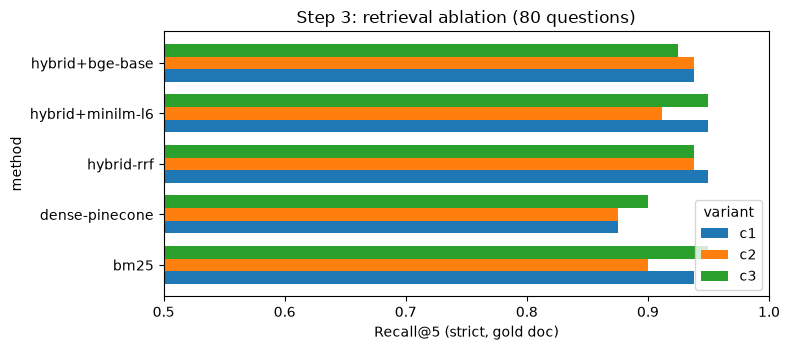

saved retrieval_v2_results.json


In [16]:
res = pd.DataFrame(RESULTS).drop_duplicates(["method", "variant"], keep="last")
cols = ["method", "variant", "doc_R@1", "doc_R@3", "doc_R@5", "doc_R@10", "doc_MRR", "page_R@5", "page_MRR"]
display(res[cols].sort_values(["doc_R@5", "doc_MRR"], ascending=False).reset_index(drop=True))

import matplotlib.pyplot as plt
piv = res.pivot(index="method", columns="variant", values="doc_R@5").reindex(
    [m for m in ["bm25", "dense-pinecone", "hybrid-rrf", "hybrid+minilm-l6", "hybrid+bge-base"] if m in set(res.method)])
ax = piv.plot(kind="barh", figsize=(8, 3.6), width=0.75)
ax.set_xlabel("Recall@5 (strict, gold doc)"); ax.set_xlim(0.5, 1.0); ax.set_title("Step 3: retrieval ablation (80 questions)")
plt.tight_layout(); plt.show()

out = {"created": time.strftime("%Y-%m-%d %H:%M"), "offline_smoke_test": OFFLINE, "config": CFG,
       "eval_set": "gitlab_eval_questions_v1_1.json (80, strict gold doc/page)", "results": res[cols].to_dict("records"),
       "rerank_latency_ms_p50_p95": {m: [round(1000 * np.percentile(x, 50)), round(1000 * np.percentile(x, 95))] for m, x in RR_LAT.items()}}
json.dump(out, open(DATA / "evaluation" / ("retrieval_v2_results" + ("_OFFLINE" if OFFLINE else "") + ".json"), "w"), indent=2)
print("saved", "retrieval_v2_results.json")

In [17]:
# >>> Record your decision here (used by policy_search below) <<<
CHOSEN_VARIANT = "c3"
CHOSEN_RERANKER = "bge-base"      # or "minilm-l6"

## 10. Calibrate `no_relevant_policy`

**Why.** Retrieval always returns *something*. To refuse honestly ("the handbook doesn't cover this"), we need a threshold on the reranker's top score. We compare the top score for our 80 in-scope questions with probes the handbook can't answer.

*These probes are for calibration in this lab only. The proper out-of-scope eval questions are a Week 1 owner task (eval v2).*

in-scope kept: 95% | probes refused: 83% | MIN_SCORE = 0.25


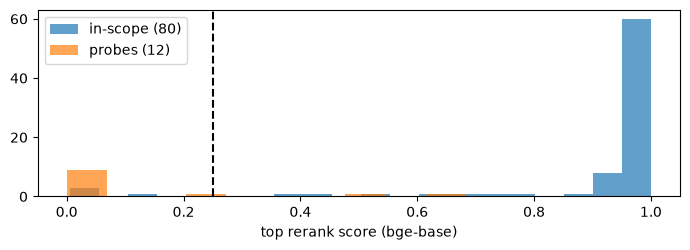

In [18]:
PROBES = ["What is the weather in Paris tomorrow?", "How do I reset my Netflix password?",
          "Write a poem about the monsoon.", "What is the capital of Australia?",
          "Which laptop should I buy under 50,000 rupees?", "Explain how a transformer neural network works.",
          "Who won the last cricket World Cup?", "What is Microsoft's parental leave policy?",
          "How do I file my Indian income tax return?", "Give me a recipe for paneer butter masala.",
          "What are Infosys's notice period rules?", "How do I fix a Python KeyError?"]
v, m = CHOSEN_VARIANT, CHOSEN_RERANKER
ins = [RR_SCORES[(m, v, e["id"])] for e in EVAL if (m, v, e["id"]) in RR_SCORES]
outs = [rerank(m, p, hybrid(v, p)[0][:CFG["rerank_in"]])[1][0] for p in PROBES]
thr_candidates = sorted(set(np.round(ins + outs, 3)))
best = max(thr_candidates, key=lambda t: (np.mean(np.array(ins) >= t) >= 0.95) * (np.mean(np.array(outs) < t)) - 1e-6 * t)
MIN_SCORE = float(best)
print(f"in-scope kept: {np.mean(np.array(ins) >= MIN_SCORE):.0%} | probes refused: {np.mean(np.array(outs) < MIN_SCORE):.0%} | MIN_SCORE = {MIN_SCORE}")
plt.figure(figsize=(7, 2.6)); plt.hist(ins, bins=20, alpha=.7, label="in-scope (80)"); plt.hist(outs, bins=10, alpha=.7, label="probes (12)")
plt.axvline(MIN_SCORE, ls="--", c="k"); plt.legend(); plt.xlabel(f"top rerank score ({m})"); plt.tight_layout(); plt.show()

**Checkpoint:** a threshold that keeps at least 95% of in-scope questions and refuses most probes. If the two histograms overlap a lot, say so in the report and rely on the critic and refusal prompt (Step 4) as a second line of defence.

## 11. Gate 12: `policy_search()` and its contract test

This is the one function the agent (Step 4) calls. Its **output shape is the contract** between retrieval and orchestration. Once the test passes, the agent owner can build against it while you keep tuning what happens inside.

In [19]:
def pack(cids, scores, max_tokens=CFG["context_tokens"]):
    out, used = [], 0
    for i, (c, s) in enumerate(zip(cids, scores), 1):
        t = LOOKUP[c]["text"]; n = int(len(t.split()) * 1.3)
        if out and used + n > max_tokens: break
        used += n
        out.append({"tag": f"C{i}", "chunk_id": c, "doc_id": LOOKUP[c]["doc_id"], "pages": LOOKUP[c]["pages"],
                    "score": round(s, 4), "text": t})
    return out

def policy_search(query: str, k: int = CFG["top_out"], variant=None, reranker=None, _force_fail=False) -> dict:
    v, m = variant or CHOSEN_VARIANT, reranker or CHOSEN_RERANKER
    if not isinstance(query, str) or not query.strip():
        return {"ok": False, "error_code": "empty_query", "message": "query must be a non-empty string"}
    t = {}; t0 = time.perf_counter(); degraded = False
    try:
        b = [c for c, _ in bm25_search(v, query, CFG["top_k_each"])]; t["bm25"] = time.perf_counter() - t0
        qv = qvec(query); t1 = time.perf_counter()
        try:
            if _force_fail: raise TimeoutError("simulated Pinecone outage")
            d = [c for c, _ in dense_pinecone(v, qv, CFG["top_k_each"])]
        except Exception:
            d, degraded = [c for c, _ in dense_faiss(v, qv, CFG["top_k_each"])], True
        t["dense"] = time.perf_counter() - t1
        cand = rrf({"bm25": b, "dense": d}, CFG["rrf_k"])[0][:CFG["rerank_in"]]
        t2 = time.perf_counter(); ids, sc = rerank(m, query, cand); t["rerank"] = time.perf_counter() - t2
    except Exception as ex:
        return {"ok": False, "error_code": "retrieval_error", "message": f"{type(ex).__name__}: {ex}"}
    top = sc[0] if sc else 0.0
    status = "ok" if top >= MIN_SCORE else "no_relevant_policy"
    chunks = pack(ids[:k], sc[:k]) if status == "ok" else []
    return {"ok": True, "data": {"status": status, "chunks": chunks,
            "tag_map": {c["tag"]: {"chunk_id": c["chunk_id"], "doc_id": c["doc_id"], "pages": c["pages"]} for c in chunks},
            "max_rerank_score": round(top, 4), "degraded": degraded, "variant": v, "reranker": m,
            "timings_ms": {x: round(1000 * y) for x, y in t.items()}}}

r = policy_search(q1["query"])
print(json.dumps({**r, "data": {**r["data"], "chunks": [{**c, "text": c["text"][:90] + "…"} for c in r["data"]["chunks"]]}}, indent=1)[:1800])

{
 "ok": true,
 "data": {
  "status": "ok",
  "chunks": [
   {
    "tag": "C1",
    "chunk_id": "doc_019::c3::000",
    "doc_id": "doc_019",
    "pages": [
     55
    ],
    "score": 0.964,
    "text": "Coding: Expense Type / Navan Policy Category: G&D (Growth & Development) Equipment: These \u2026"
   },
   {
    "tag": "C2",
    "chunk_id": "doc_019::c3::003",
    "doc_id": "doc_019",
    "pages": [
     55,
     56
    ],
    "score": 0.8565,
    "text": "New Hires- 1,500 USD (or equivalent local currency) Guidelines: Purchase the items you nee\u2026"
   },
   {
    "tag": "C3",
    "chunk_id": "doc_022::c3::006",
    "doc_id": "doc_022",
    "pages": [
     65
    ],
    "score": 0.7961,
    "text": "CXC Global: Physical Cards Please see Navan Physical Card policy here. 6. Purchase Cards N\u2026"
   },
   {
    "tag": "C4",
    "chunk_id": "doc_019::c3::001",
    "doc_id": "doc_019",
    "pages": [
     55
    ],
    "score": 0.1844,
    "text": "Equipment: Although we don\u2019t 

In [20]:
# ---- contract test (port to tests/test_retrieval.py) ----
def check_contract(r):
    assert set(r) >= {"ok"}
    if not r["ok"]:
        assert {"error_code", "message"} <= set(r); return
    d = r["data"]
    assert d["status"] in {"ok", "no_relevant_policy"}
    assert isinstance(d["degraded"], bool) and isinstance(d["max_rerank_score"], float)
    assert len(d["chunks"]) <= CFG["top_out"]
    for i, c in enumerate(d["chunks"], 1):
        assert c["tag"] == f"C{i}" and c["chunk_id"] in LOOKUP and c["pages"] and c["text"]
        assert d["tag_map"][c["tag"]]["chunk_id"] == c["chunk_id"]
    assert sum(len(c["text"].split()) * 1.3 for c in d["chunks"]) <= CFG["context_tokens"] + 400
    if d["status"] == "no_relevant_policy":
        assert d["chunks"] == []

for e in EVAL[:5]:
    check_contract(policy_search(e["query"]))
check_contract(policy_search(""))                                   # error envelope
fail = policy_search(q1["query"], _force_fail=True); check_contract(fail)
assert fail["data"]["degraded"] is True                             # FAISS took over
check_contract(policy_search("What is the weather in Paris tomorrow?"))
print("Contract test passed ✓  | fallback works ✓  | refusal path ✓")

Contract test passed ✓  | fallback works ✓  | refusal path ✓


## 12. Gate checklist and what to commit

| Gate | Done when | ✓ |
|---|---|---|
| 5 Strict metric | Section 1 shows the false-hit rate; all tables use gold doc/page | ☐ |
| 8 Chunking | C1–C3 compared on BM25, dense, hybrid and rerank (section 9 table) | ☐ |
| 10 Cache / namespaces / fallback | `embedding_cache.npz`, `lab-c1..c3` counts match, Pinecone ≈ FAISS | ☐ |
| 6 RRF | Section 5.1 result recorded; section 7 shows chunks matched by **both** | ☐ |
| 7 Reranker | Both models compared on accuracy **and** latency; choice recorded in ADR-002 | ☐ |
| 9 Page citations | Every chunk in `policy_search` output has `pages` | ☐ |
| 12 Contract test | Section 11 passes | ☐ |

**Commit:** `data/evaluation/retrieval_v2_results.json`, this notebook (with outputs), and the review files. Don't commit `data/lab/embedding_cache.npz`; add `data/lab/` to `.gitignore`.

**Then port to `src/`** (Fri 20): `lab_core` → `src/retrieval/chunker.py` (add C2, C3, page tagging); `bm25_search` / `dense_*` / `rrf` / `rerank` / `policy_search` → `src/retrieval/policy_search.py` (replacing `hybrid_search.py` and the empty `reranker.py`); the contract test → `tests/test_retrieval.py`. After that comes Step 4 (M1): wrap `policy_search` as the agent's one tool.